# Assignment 2: Training the Fully Recurrent Network

*Author:* Thomas Adler

*Copyright statement:* This  material,  no  matter  whether  in  printed  or  electronic  form,  may  be  used  for  personal  and non-commercial educational use only.  Any reproduction of this manuscript, no matter whether as a whole or in parts, no matter whether in printed or in electronic form, requires explicit prior acceptance of the authors.


## Exercise 1: Data generation

There are two classes, both occurring with probability 0.5. There is one input unit. Only the first sequence element conveys relevant information about the class. Sequence elements at positions $t > 1$ stem from a Gaussian with mean zero and variance 0.2. The first sequence element is 1.0 (-1.0) for class 1 (2). Target at sequence end is 1.0 (0.0) for class 1 (2)

Write a function `generate_data` that takes an integer `T` as argument which represents the sequence length. Seed the `numpy` random generator with the number `0xDEADBEEF`. Implement the [Python3 generator](https://docs.python.org/3/glossary.html#term-generator) pattern and produce data in the way described above. The input sequences should have the shape `(T, 1)` and the target values should have the shape `(1,)`.

In [1]:
%matplotlib inline
import numpy as np
from scipy.special import expit as sigmoid
import matplotlib.pyplot as plt

class FullyRecurrentNetwork(object):
    def __init__(self, D, I, K):
        self.W = np.random.uniform(-0.01, 0.01, (I, D))
        self.R = np.random.uniform(-0.01, 0.01, (I, I))
        self.V = np.random.uniform(-0.01, 0.01, (K, I))
    
    def forward(self, x, y):
        # helper function for numerically stable loss
        def f(z):
            return np.log1p(np.exp(-np.absolute(z))) + np.maximum(0, z)
        
        # infer dims
        T, D = x.shape
        K, I = self.V.shape

        # init result arrays
        self.x = x
        self.y = y
        self.a = np.zeros((T, I))

        # iterate forward in time 
        # trick: access self.a[-1] in first iteration
        for t in range(T):
            self.a[t] = np.tanh(self.W @ x[t] + self.R @ self.a[t-1])
            
        self.z = self.V @ self.a[t]
        return y * f(-self.z) + (1-y) * f(self.z)

T, D, I, K = 10, 3, 5, 1
model = FullyRecurrentNetwork(D, I, K)
model.forward(np.random.uniform(-1, 1, (T, D)), 1)

def generate_data(T):
    ########## YOUR SOLUTION HERE ##########
    np.random.seed(0xDEADBEEF)
    while True:
        class_label = np.random.choice([1,2])
        sequence = np.random.normal(0, np.sqrt(0.2), (T,1))
        if class_label == 1:
            sequence[0] = 1.0
            target = np.array([1.0])
        else:
            sequence[0] = -1.0
            target = np.array([0.0])
        yield sequence, target

data = generate_data(20)
next_iter = next(data)
print(next_iter)
print(next_iter[0].shape)
print(next_iter[1].shape)

(array([[-1.        ],
       [ 0.41371384],
       [-0.13775049],
       [-0.45355367],
       [ 0.7960085 ],
       [-0.75446062],
       [ 0.3067845 ],
       [-0.09481291],
       [-0.45504802],
       [ 0.11627078],
       [ 0.20636565],
       [ 0.37111345],
       [-0.4933726 ],
       [-0.4775466 ],
       [ 0.00499703],
       [ 0.58204209],
       [ 0.14235316],
       [-0.19386339],
       [-0.0527816 ],
       [ 0.05914056]]), array([0.]))
(20, 1)
(1,)


## Exercise 2: Gradients for the network parameters
Compute gradients of the total loss 
$$
L = \sum_{t=1}^T L(t), \quad \text{where} \quad L(t) = L(z(t), y(t))
$$
w.r.t. the weights of the fully recurrent network. To this end, find the derivative of the loss w.r.t. the logits and hidden pre-activations first, i.e., 
$$
\psi^\top(t) = \frac{\partial L}{\partial z(t)} \quad \text{and} \quad \delta^\top(t) = \frac{\partial L}{\partial s(t)}.
$$
With the help of these intermediate results you should be able to compute the gradients w.r.t. the weights, i.e., $\nabla_W L, \nabla_R L, \nabla_V L$. 

*Hint: Take a look at the computational graph from the previous assignment to see the functional dependencies.*

*Remark: Although we only have one label at the end of the sequence, we consider the more general case of evaluating a loss at every time step in this exercise (many-to-many mapping).*

########## YOUR SOLUTION HERE ##########

$$z(t) = V a(t)$$
$$s(t) = W x(t) + R a(t-1)$$
$$a(t) = \tanh(s(t))$$
$$\hat y(t) = \sigma(z(t))$$

Matrix dims:

$$W \in \mathbb{R}^{I \times D}$$
$$R \in \mathbb{R}^{I \times I}$$
$$V \in \mathbb{R}^{K \times I}$$
$$x(t) \in \mathbb{R}^{D \times 1}$$
$$s(t) \in \mathbb{R}^{I \times 1}$$
$$a(t) \in \mathbb{R}^{I \times 1}$$
$$z(t) \in \mathbb{R}^{K \times 1}$$

Using $s(t) = Wx(t) + Ra(t-1)$ and taking the derivative w.r.t $W$, we get:

(x and a are column vectors, they need to be transposed)

$\frac{\partial s(t)}{\partial W} = x(t)^\top$

$\nabla_W L = \sum_{t=1}^T \frac{\partial L}{\partial s(t)} \frac{\partial s(t)}{\partial W} = \sum_{t=1}^T \delta(t) x(t)^\top$ (where $\delta(t) = \frac{\partial L}{\partial s(t)}$ that is the derivative of the loss w.r.t the hidden pre-activation at time $t$)

Using $s(t) = Wx(t) + Ra(t-1)$ and taking the derivative w.r.t $R$, we get:

$\frac{\partial s(t)}{\partial R} = a(t-1)^\top$

$\nabla_R L = \sum_{t=1}^T \frac{\partial L}{\partial s(t)} \frac{\partial s(t)}{\partial R} = \sum_{t=1}^T \delta(t) a(t-1)^\top$

Using $z(t) = Va(t)$, the gradient of the loss w.r.t $V$:

$\nabla_V L = \sum_{t=1}^T \frac{\partial L}{\partial z(t)} \frac{\partial z(t)}{\partial V}$

$\psi(t) = \frac{\partial L}{\partial z(t)} = \sigma(z(t)) - y(t)$

$\frac{\partial z(t)}{\partial V} = a(t)^\top$

Combining with $\psi(t)$, we get:

$\nabla_V L = \sum_{t=1}^T \psi(t) a(t)^\top$

Backprop for $\delta(t)$:

$\delta(t) = \frac{\partial L}{\partial s(t)} = \frac{\partial L}{\partial a(t)} \frac{\partial a(t)}{\partial s(t)}$

Derivative wrt $a(t)$:

$\frac{\partial L}{\partial a(t)} = \frac{\partial L}{\partial z(t)} \frac{\partial z(t)}{\partial a(t)} + \frac{\partial L}{\partial s(t+1)} \frac{\partial s(t+1)}{\partial a(t)}$ (where the first term is for time step t and second term is for time step t+1 (recurrent))

$\frac{\partial z(t)}{\partial a(t)} = V$

$\frac{\partial s(t+1)}{\partial a(t)} = R$

Combining both we get:

$\frac{\partial L}{\partial a(t)} = V^\top \psi(t) + R^\top \delta(t+1)$

Since $a(t) = \tanh(s(t))$ and the derivative of $tanh(s)$ is $(1 - tanh^2(s))$:

$\frac{\partial a(t)}{\partial s(t)} = \text{diag}(1 - a(t) \odot a(t))$

Combining all in a single expression:

$$\delta(t) = \left( V^\top \psi(t) + R^\top \delta(t+1) \right) \odot (1 - a(t) \odot a(t))$$


## Exercise 3: The backward pass
Write a function `backward` that takes a model `self` as argument. The function should compute the gradients of the loss with respect to all model parameters and store them to `self.dW`, `self.dR`, `self.dV`, respectively. 

In [2]:
def backward(self):
    ########## YOUR SOLUTION HERE ##########
    a,x,y,z = self.a, self.x, self.y, self.z
    W,R,V = self.W, self.R, self.V
    T, D = x.shape
    I = W.shape[0]

    self.dW = np.zeros_like(W)
    self.dR = np.zeros_like(R)
    self.dV = np.zeros_like(V)

    psi = sigmoid(z) - y
    self.dV += psi.reshape(K, 1) @ a[-1].reshape(1, I) #many to one
    delta = (V.T @ psi).reshape(I,) * (1 - a[-1]**2) #psi(t)

    for t in reversed(range(T)):
        self.dW += np.outer(delta, x[t].reshape(D,))
        if t > 0:
            self.dR += np.outer(delta, a[t-1])
            delta = (R.T @ delta) * (1 - a[t-1]**2) #R^T * delta(t+1)

FullyRecurrentNetwork.backward = backward
model.backward()

## Exercise 4: Gradient checking
Write a function `grad_check` that takes a model `self`, a float `eps` and another float `thresh` as arguments and computes the numerical gradients of the model parameters according to the approximation
$$
f'(x) \approx \frac{f(x + \varepsilon) - f(x - \varepsilon)}{2 \varepsilon}.
$$
If any of the analytical gradients are farther than `thresh` away from the numerical gradients the function should throw an error. 

In [3]:
def grad_check(self, eps, thresh):
    ########## YOUR SOLUTION HERE ##########
    num_dW = np.zeros_like(self.W)
    num_dR = np.zeros_like(self.R)
    num_dV = np.zeros_like(self.V)

    for i in range(self.W.shape[0]):
        for j in range(self.W.shape[1]):
            self.W[i,j] += eps
            loss_plus = self.forward(self.x, self.y)
            self.W[i,j] -= 2*eps
            loss_minus = self.forward(self.x, self.y)
            self.W[i,j] += eps
            num_dW[i,j] = (loss_plus-loss_minus) / (2*eps)

    for i in range(self.R.shape[0]):
        for j in range(self.R.shape[1]):
            self.R[i,j] += eps
            loss_plus = self.forward(self.x, self.y)
            self.R[i,j] -= 2*eps
            loss_minus = self.forward(self.x, self.y)
            self.R[i,j] += eps
            num_dR[i,j] = (loss_plus-loss_minus) / (2*eps)

    for i in range(self.V.shape[0]):
        for j in range(self.V.shape[1]):
            self.V[i,j] += eps
            loss_plus = self.forward(self.x, self.y)
            self.V[i,j] -= 2*eps
            loss_minus = self.forward(self.x, self.y)
            self.V[i,j] += eps
            num_dV[i,j] = (loss_plus-loss_minus) / (2*eps)

    #print(num_dW)
    #print(num_dR)
    #print(num_dV)

    if np.max(np.abs(self.dW - num_dW)) > thresh:
        raise ValueError("gradient check failed | W")

    if np.max(np.abs(self.dR - num_dR)) > thresh:
        raise ValueError("gradient check failed | R")

    if np.max(np.abs(self.dV - num_dV)) > thresh:
        raise ValueError("gradient check failed | V")

    print("passed gradient check")

FullyRecurrentNetwork.grad_check = grad_check
model.grad_check(1e-7, 1e-7)

passed gradient check


## Exercise 5: Parameter update

Write a function `update` that takes a model `self` and a float argument `eta`, which represents the learning rate. The method should implement the gradient descent update rule $\theta \gets \theta - \eta \nabla_{\theta}L$ for all model parameters $\theta$.

In [4]:
def update(self, eta):
    ########## YOUR SOLUTION HERE ##########
    self.W -= eta*self.dW
    self.R -= eta*self.dR
    self.V -= eta*self.dV

FullyRecurrentNetwork.update = update
model.update(0.001)

## Exercise 6: Network training

Train the fully recurrent network with 32 hidden units. Start with input sequences of length one and tune the learning rate and the number of update steps. Then increase the sequence length by one and tune the hyperparameters again. What is the maximal sequence length for which the fully recurrent network can achieve a performance that is better than random? Visualize your results. 

Sequence length: 1 | Accuracy 100.00%
Sequence length: 2 | Accuracy 98.73%
Sequence length: 3 | Accuracy 50.20%
Sequence length: 4 | Accuracy 81.33%
Sequence length: 5 | Accuracy 50.24%
Sequence length: 10 | Accuracy 49.68%


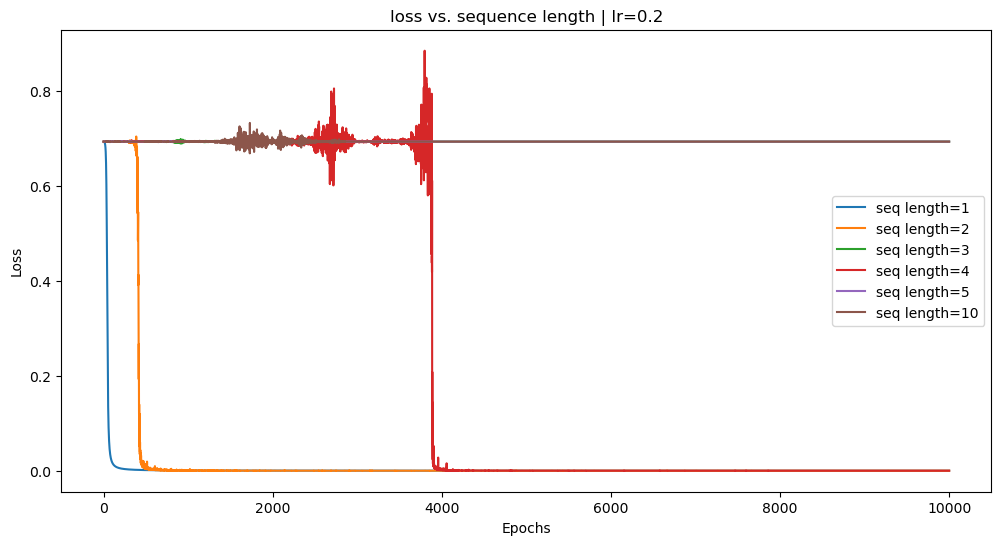

In [5]:
########## YOUR SOLUTION HERE ##########
def train(seq_lens, hiddens=32, lr=0.2, epochs=10000):
    results = {}
    accs = {}
    
    for seq_len in seq_lens:
        model = FullyRecurrentNetwork(D=1, I=hiddens, K=1)
        data_gen = generate_data(seq_len)
        losses = []
        correct = 0
        total = 0
        
        for epoch in range(epochs):
            x, y = next(data_gen)
            loss = model.forward(x, y)
            losses.append(loss)
            model.backward()
            model.update(lr)

            pred = sigmoid(model.z) >= 0.5
            if pred == y:
                correct += 1
            total += 1

        results[seq_len] = losses
        accs[seq_len] = correct / total

    for seq_len, acc in accs.items():
        print(f"Sequence length: {seq_len} | Accuracy {acc:.2%}")

    plt.figure(figsize=(12, 6))
    for seq_len, losses in results.items():
        plt.plot(range(epochs), losses, label=f"seq length={seq_len}")
    
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title(f"loss vs. sequence length | lr={lr}")
    plt.legend()
    plt.show()

seq_lens = [1, 2, 3, 4, 5, 10]
train(seq_lens)

## Exercise 7: The Vanishing Gradient Problem

Analyze why the network is incapable of learning long-term dependencies. Show that $\|\frac{\partial a(T)}{\partial a(1)}\|_2 \leq \|R\|_2^{T-1}$ , where $\|\cdot\|_2$ is the spectral norm, and discuss how that affects the propagation of error signals through the time dimension of the network. 

*Hint: Use the fact that the spectral norm is submultiplicative for square matrices, i.e. $\|AB\|_2 \leq \|A\|_2\|B\|_2$ if $A$ and $B$ are both square.*

########## YOUR SOLUTION HERE ##########